#Model C: Word TF-IDF + Multinomial Naive Bayes (Michelle Wang)

In [1]:
import sys
from pathlib import Path
import time
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from sklearn.model_selection import train_test_split

#Data Loading & Shared Split
Load competition data from the team's shared zip file and apply the team's standardized 8,000/2,000 train-validation split.

In [3]:
project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Add project root to sys.path so data_utils can be imported
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

# Import team's shared loading and splitting functions
from data_utils import load_data, split_data

# Path to the zip archive inside the gitignored data folder
zip_path = project_dir / "data" / "cornell-tech-cs-5785-combined-2026-ai-vs-human-text.zip"

# Load directly from zip archive and perform shared stratified split
train, unlabeled, test = load_data(zip_path)
train_df, val_df = split_data(train)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test.shape)

Training: (8000, 3)
Validation: (2000, 3)
Test: (3000, 2)


#Baseline Model: Word TF-IDF + Multinomial Naive Bayes
Initial baseline using word unigrams and bigrams with default Laplace smoothing ($\alpha = 1.0$).

In [5]:
model_nb = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,       # convert all text to lowercase
        ngram_range=(1, 2),   # extract single words (unigrams) and 2-word pairs (bigrams)
        min_df=2,             # only take words appearing at least twice
        max_features=50000   
    )),
    ("nb", MultinomialNB(
        alpha=1.0             # standard baseline Laplace smoothing
    ))
])

# Train the baseline model on the 8000 training samples
start_time = time.perf_counter()
model_nb.fit(train_df["text"], train_df["label"])
train_time = time.perf_counter() - start_time
print(f"Train time: {train_time:.2f} seconds")


Train time: 6.15 seconds
Train AUROC: 0.9688
Validation AUROC: 0.8783


In [6]:
# Predict probability of label 1 (AI-generated) using the second column
train_prob = model_nb.predict_proba(train_df["text"])[:, 1]
val_prob = model_nb.predict_proba(val_df["text"])[:, 1]

# Compute AUROC
train_auc = roc_auc_score(train_df["label"], train_prob)
val_auc = roc_auc_score(val_df["label"], val_prob)

print(f"Train AUROC: {train_auc:.4f}")
print(f"Validation AUROC: {val_auc:.4f}")

Train AUROC: 0.9688
Validation AUROC: 0.8783


#Hyperparameter Turning: Laplace Smoothing ($\alpha$) Sweep
Compare different additive smoothing parameters ($\alpha$) using fixed TF-IDF features to optimize validation AUROC.

In [8]:
# Transform text once using the fitted baseline vectorizer
X_train_nb = model_nb.named_steps["tfidf"].transform(train_df["text"])
X_val_nb = model_nb.named_steps["tfidf"].transform(val_df["text"])
y_train = train_df["label"]
y_val = val_df["label"]

# Evaluate logarithmic range of alpha values
alpha_values = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
grid_results = []

for v in alpha_values:
    # Initialize and fit Naive Bayes with specific alpha
    model = MultinomialNB(alpha=v)
    model.fit(X_train_nb, y_train)

    # Predict positive class probabilities
    train_prob = model.predict_proba(X_train_nb)[:, 1]
    val_prob = model.predict_proba(X_val_nb)[:, 1]

    # Record AUROC metrics
    grid_results.append({
        "Alpha": v,
        "Train AUROC": roc_auc_score(y_train, train_prob),
        "Validation AUROC": roc_auc_score(y_val, val_prob)
    })

# Format comparison table (OUTSIDE the loop)
grid_df = pd.DataFrame(grid_results)
print(grid_df.round(4).to_string(index=False))

# Identify optimal alpha achieving highest validation AUROC
optimal_alpha = grid_df.loc[grid_df["Validation AUROC"].idxmax(), "Alpha"]
print(f"\nOptimal Alpha: {optimal_alpha}")

 Alpha  Train AUROC  Validation AUROC
 0.001       0.9939            0.8778
 0.010       0.9920            0.8804
 0.050       0.9892            0.8816
 0.100       0.9871            0.8819
 0.500       0.9768            0.8806
 1.000       0.9688            0.8783
 2.000       0.9584            0.8750
 5.000       0.9425            0.8694
10.000       0.9307            0.8653

Optimal Alpha: 0.1


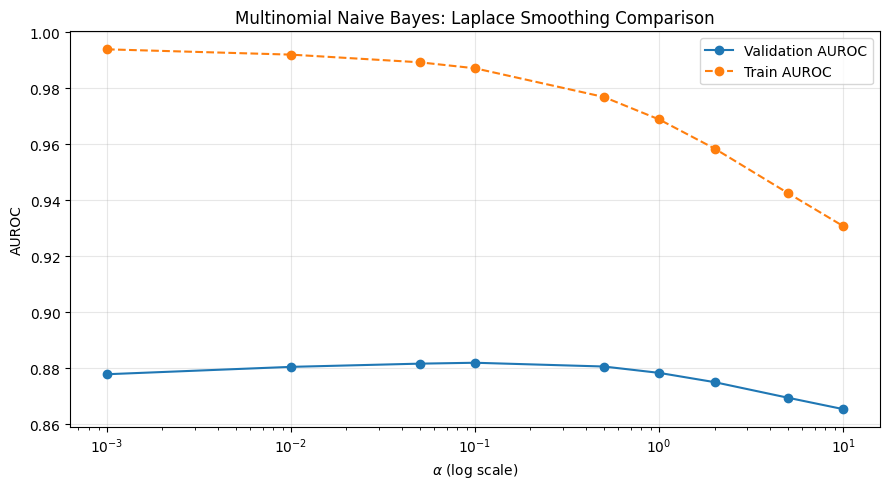

In [9]:
#plot the curve on validation and training AUROC across alpha values 
plt.figure(figsize=(9, 5))
plt.plot(grid_df["Alpha"], grid_df["Validation AUROC"], marker="o", label="Validation AUROC")
plt.plot(grid_df["Alpha"], grid_df["Train AUROC"], marker="o", linestyle="--", label="Train AUROC")

plt.xscale("log")  # use log scale because alpha values span multiple orders of magnitude
plt.xlabel(r"$\alpha$ (log scale)")
plt.ylabel("AUROC")
plt.title("Multinomial Naive Bayes: Laplace Smoothing Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Retrain on Full Dataset & Final Kaggle Submission
Retrain the Multinomial Naive Bayes pipeline on all 10,000 labeled samples using the tuned smoothing parameter (`alpha = 0.1`), generate positive-class test probabilities, verify submission formatting, and export the final CSV.

In [10]:
# recreate best tuned Naive Bayes model
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000
    )),
    ("nb", MultinomialNB(alpha=optimal_alpha))
])

# train on all 10,000 labeled ex
final_model.fit(train["text"], train["label"])

# predict probability of AI-generated text for Kaggle test data
test_probs = final_model.predict_proba(test["text"])[:, 1]

print(f"Training examples: {len(train)}")
print(f"Test predictions: {len(test_probs)}")

Training examples: 10000
Test predictions: 3000


In [11]:
sample_submission_path = data_dir / "sample_submission.csv"
submission = pd.read_csv(sample_submission_path)

# identify prediction column
prediction_cols = [col for col in submission.columns if col != "id"]
assert len(prediction_cols) == 1
prediction_col = prediction_cols[0]

# match predicted probabilities to correct test IDs
prob_by_id = pd.Series(test_probs, index=test["id"])
submission[prediction_col] = submission["id"].map(prob_by_id)

# verify submission before saving
assert len(submission) == len(test)
assert submission[prediction_col].notna().all()
assert submission[prediction_col].between(0, 1).all()

# save submission file directly to Desktop
desktop_dir = Path.home() / "Desktop"
output_path = desktop_dir / "submission_multinomial_nb.csv"

submission.to_csv(output_path, index=False)

print(f"Saved to: {output_path}")
print(submission.head())

Saved to: /Users/michellewang/Desktop/submission_multinomial_nb.csv
      id     label
0  13001  0.993405
1  13002  0.291014
2  13003  0.837707
3  13004  0.034174
4  13005  0.890112
